# Meteorite landings: exploration

The original exploration behind this repo: load NASA's Meteorite Landings dataset, clean out records that can't be placed on a map, and scatter every meteorite by longitude and latitude. With enough points, the continents draw themselves.

The cleaning rules now live in [`meteorites.py`](../meteorites.py) so this notebook, `build.py` and the interactive map all agree.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import meteorites as M

raw = M.load_raw()
raw.head(7)

,name,id,nametype,recclass,mass,fall,year,reclat,reclong,GeoLocation
0,Aachen,1,Valid,L5,21.0,Fell,1880.0,50.77500,6.08333,"(50.775, 6.08333)"
1,Aarhus,2,Valid,H6,720.0,Fell,1951.0,56.18333,10.23333,"(56.18333, 10.23333)"
2,Abee,6,Valid,EH4,107000.0,Fell,1952.0,54.21667,-113.00000,"(54.21667, -113.0)"
3,Acapulco,10,Valid,Acapulcoite,1914.0,Fell,1976.0,16.88333,-99.90000,"(16.88333, -99.9)"
4,Achiras,370,Valid,L6,780.0,Fell,1902.0,-33.16667,-64.95000,"(-33.16667, -64.95)"
5,Adhi Kot,379,Valid,EH4,4239.0,Fell,1919.0,32.10000,71.80000,"(32.1, 71.8)"
6,Adzhi-Bogdo (stone),390,Valid,LL3-6,910.0,Fell,1949.0,44.83333,95.16667,"(44.83333, 95.16667)"


## Raw coordinates

Plotting everything as-is shows the problems: a big pile at (0, 0) and one point far outside the map (longitude 354).

missing coordinates: 7315
at (0, 0): 6214


,name,recclass,fall,year,reclat,reclong
22946,Meridiani Planum,"Iron, IAB complex",Found,2005.0,-1.94617,354.47333


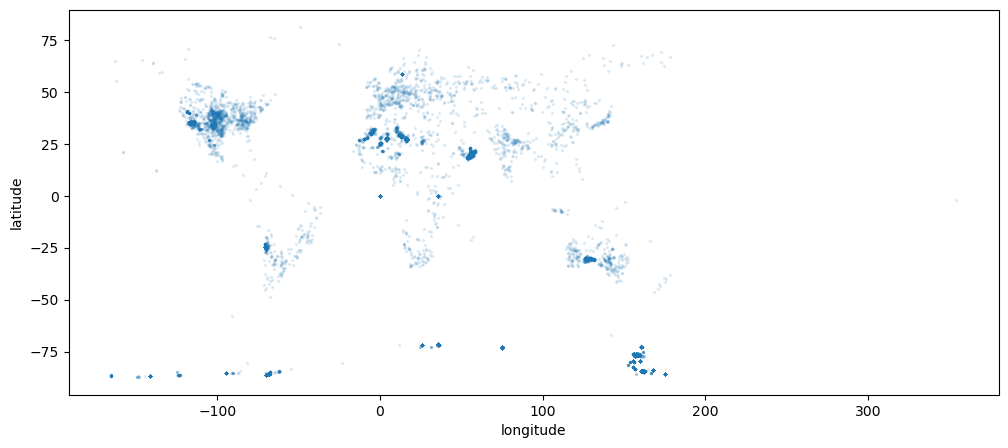

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(raw.reclong, raw.reclat, alpha=0.1, s=2)
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
print('missing coordinates:', raw.reclat.isna().sum())
print('at (0, 0):', ((raw.reclat == 0) & (raw.reclong == 0)).sum())
raw[raw.reclong > 180][['name', 'recclass', 'fall', 'year', 'reclat', 'reclong']]

That outlier is *Meridiani Planum*, an iron meteorite found **on Mars** by the Opportunity rover. Not a landing on Earth, so it goes.

## Cleaned

`M.clean` drops missing and (0, 0) coordinates, the Mars record, and 223 Yamato finds whose latitude was recorded as 0. Implausible years (e.g. 2101) become unknown instead of being dropped.

45,716 records, 31,963 can be mapped


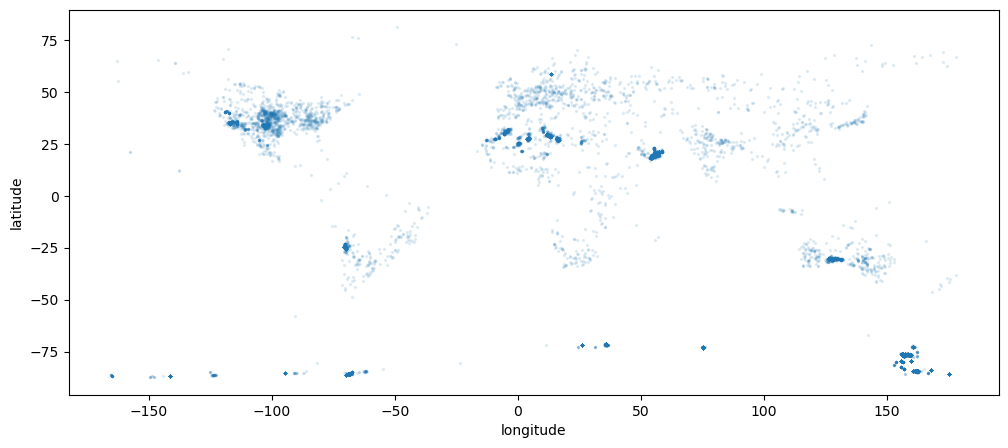

In [3]:
df = M.clean(raw)
m = df[df.mappable]
print(f'{len(df):,} records, {len(m):,} can be mapped')

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(m.reclong, m.reclat, alpha=0.1, s=2)
ax.set_xlabel('longitude'); ax.set_ylabel('latitude');

## Colour by year, size by mass

The original plot: darker = older, bigger = heavier. Mass spans eight orders of magnitude, so the size uses `log10(mass)`; a linear scale makes everything but the Hoba meteorite invisible.

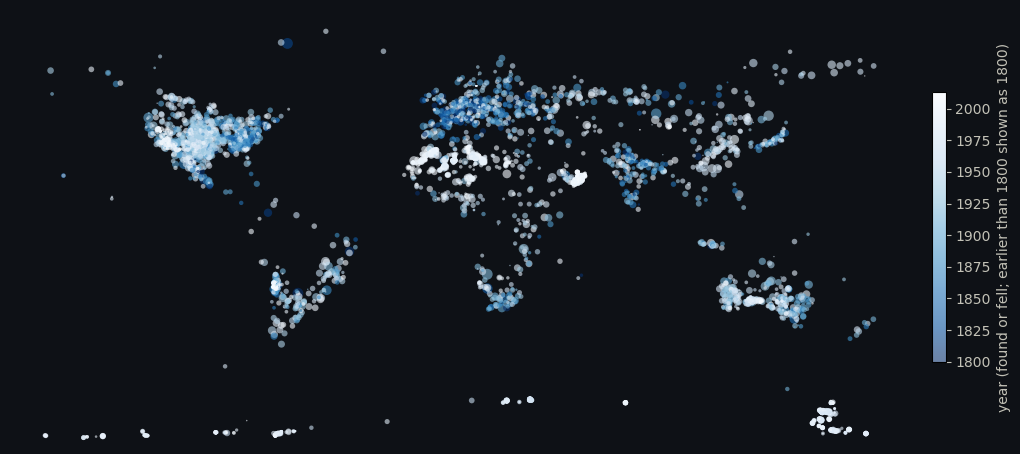

In [4]:
dated = m.dropna(subset=['year']).sort_values('mass', ascending=False)
size = 1 + np.log10(dated.mass.fillna(1) + 1) ** 2

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#0e1116')
ax.set_facecolor('#0e1116')
sc = ax.scatter(dated.reclong, dated.reclat, c=dated.year.clip(1800), s=size,
                cmap='Blues_r', alpha=0.6, linewidths=0)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_aspect('equal'); ax.axis('off')
cb = fig.colorbar(sc, ax=ax, shrink=0.5, label='year (found or fell; earlier than 1800 shown as 1800)')
cb.ax.yaxis.label.set_color('#c3c2b7'); cb.ax.tick_params(colors='#c3c2b7')

## A few numbers

Everything quoted in the README comes from `M.insights` (also saved to `data/insights.json` by `build.py`).

In [5]:
ins = M.insights(df)
print(f"found: {ins['found']:,}   seen falling: {ins['fell']:,}")
print(f"located meteorites south of 60 S: {ins['antarctica_share_of_mapped']:.1%}")
print(f"median mass, found: {ins['median_mass_g_found']:,.1f} g   fell: {ins['median_mass_g_fell']:,.0f} g")
ins['groups'].round(3)

found: 44,609   seen falling: 1,107
located meteorites south of 60 S: 69.1%
median mass, found: 30.5 g   fell: 2,800 g


,count,mass_kg,count_share,mass_share
group,,,,
Ordinary chondrite,39843,59497.771,0.872,0.098
Carbonaceous chondrite,1584,3535.099,0.035,0.006
Other chondrite,688,964.559,0.015,0.002
Achondrite,1837,5960.229,0.040,0.010
Lunar / Martian,284,188.435,0.006,0.000
Iron,1069,514527.666,0.023,0.850
Stony-iron,281,20284.764,0.006,0.034
Unclassified,130,322.689,0.003,0.001


In [6]:
ins['heaviest'][['name', 'recclass', 'mass', 'fall', 'year']].assign(tonnes=lambda d: d.mass / 1e6)

,name,recclass,mass,fall,year,tonnes
16392,Hoba,"Iron, IVB",60000000.0,Found,1920.0,60.0
5373,Cape York,"Iron, IIIAB",58200000.0,Found,1818.0,58.2
5365,Campo del Cielo,"Iron, IAB-MG",50000000.0,Found,1575.0,50.0
5370,Canyon Diablo,"Iron, IAB-MG",30000000.0,Found,1891.0,30.0
3455,Armanty,"Iron, IIIE",28000000.0,Found,1898.0,28.0
12613,Gibeon,"Iron, IVA",26000000.0,Found,1836.0,26.0
5468,Chupaderos,"Iron, IIIAB",24300000.0,Found,1852.0,24.3
26297,Mundrabilla,"Iron, IAB-ung",24000000.0,Found,1911.0,24.0
920,Sikhote-Alin,"Iron, IIAB",23000000.0,Fell,1947.0,23.0
5016,Bacubirito,"Iron, ungrouped",22000000.0,Found,1863.0,22.0
